<h1>Section 3 – Unsupervised learning – clustering</h1>
In this unsupervised learning task, the objective is to cluster Reddit comments based on the words used
within the comments in them. The aim is to identify patterns and group comments with similar words
together.

<h2>Kmeans</h2>

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [2]:
data=pd.read_csv("data_unsupervised.csv", encoding="utf8")[:10000]

data['body'] = data['body'].str.lower()#to lowercase
data['body'] = data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
data['body'] = data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace

#data = data[~(data['body'].str.len() < 10)] #drop comments with less than 10 characters
#data = data[~(data['body'].str.len() > 500)] #drop comments with more than 500 characters

data=data.dropna()
data=data.drop_duplicates()

lemmatizer = WordNetLemmatizer()
data['body'] = data['body'].apply(lambda x: ' '.join([lemmatizer.lemmatize(word) for word in word_tokenize(x)]))

word_counts = data['body'].str.split().explode().value_counts()    
words_once = set(word_counts[word_counts == 1].index)#words that appear only once
most_freq_words = set(word_counts.nlargest(100).index)#most common words treated as stop words
remove_words = words_once | most_freq_words

def remove_selected_words(text):
    return ' '.join([word for word in text.split() if word not in remove_words])

data['body'] = data['body'].apply(remove_selected_words)

data['body'] = data['body'].str.strip() #remove leading and trailing whitespace
data = data[~(data['body'] == '')] #drop empty comments
data = data.drop_duplicates(subset=['body'])
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(data['body'])

In [6]:
print(words_once)

{'constellation', 'dempsey', 'fearing', 'mai', 'rtumblrinaction', 'shithole', 'odyn', 'picturesmodel', 'ff', 'astrill', 'handcuff', 'agender', 'dedicating', 'pellet', 'poekuhmon', 'huntsman', 'benzoyl', 'clime', 'sweating', 'overweening', 'pinhead', 'cutter', 'dramalicious', 'latoya', 'oligopolic', 'zooey', 'gonad', 'kalashnikov', 'birthdate', 'timelords', 'zealander', 'doms', 'portfolio', 'unsaid', 'hemingway', 'middleground', 'krank', 'lorkhans', 'nowhe', 'whitest', 'cognitive', 'frisbee', 'apa', 'shinji', 'deb', 'rwickededge', 'whatd', 'sail', 'exif', 'rex', 'clicker', 'psychic', 'hyun', 'fsbatmareor', 'kswiss', 'fivenil', 'glimpse', 'flue', 'healthheart', 'multiyear', 'ensued', 'nb', 'hulking', 'rt', 'disagre', 'raimi', 'cocooning', 'informing', 'encapsulate', 'resembles', 'selecting', 'septic', 'owed', 'attorney', 'gnostic', 'rciv', 'immigrant', 'formalityversatile', 'tremor', 'firstly', 'greg', 'nonedited', 'tahn', 'thd', 'overinflating', 'embarrassment', 'schaue', 'hulu', 'bette

In [3]:
from sklearn.preprocessing import MaxAbsScaler
from sklearn.decomposition import TruncatedSVD

# svd = TruncatedSVD(n_components=1000)
# X = svd.fit_transform(X)
# print("Explained variance by SVD:", svd.explained_variance_ratio_.sum())

X = MaxAbsScaler().fit_transform(X)
X=X*5

silhouette score computed:  0.5449084560857871
silhouette score computed:  0.35631948243608735
silhouette score computed:  0.07714950971028903
silhouette score computed:  0.44168766635059065
silhouette score computed:  0.08868011709424094
silhouette score computed:  0.29290327284816686
silhouette score computed:  0.22840313957336444


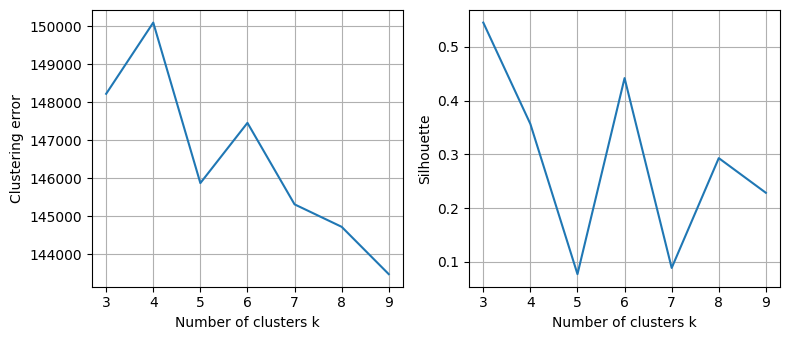

In [5]:
n_clusters=2
kmeans = KMeans(
    n_clusters, #will be choosen later
    #init='random', #centroids are initialized randomly TOO SLOW
    init='k-means++', #centroids are equally spaced -> probably better than random initialization. and should converge faster
    random_state=None, 
    n_init='auto', #number of times the k-means algorithm will be run with different centroid seeds. 'auto' uses a default value based on init
    max_iter=15
    )
clustering_results = []
k_values=pd.Series(range(3, 10, 1))#this will need to be changed
for k in k_values:
    clustering_results.append(KMeans(n_clusters=k).fit(X))
    #print(f"Fitted KMeans with {k} clusters")#just to have a reference to how much time it's taking to execute

n_sample=10000
silhouetteScores = []
for result in clustering_results:
    try:
        silhouetteScores.append(silhouette_score(X, result.labels_, sample_size=n_sample))
        print("silhouette score computed: ", silhouetteScores[-1])
    except ValueError as e:
        print(f"Skipping silhouette calculation due to error: {e}")
        silhouetteScores.append(-1)

# Plotting the results
fig, axs = plt.subplots(1,2, figsize=(8, 3.5))
axs[0].plot(
    [k for k in k_values], 
    [result.inertia_ for result in clustering_results]
)
axs[0].set_xlabel("Number of clusters k")
axs[0].set_ylabel("Clustering error")
axs[0].grid()
axs[1].plot(
    [k for k in k_values], 
    [s for s in silhouetteScores]
)
axs[1].set_xlabel("Number of clusters k")
axs[1].set_ylabel("Silhouette")
axs[1].grid()
plt.tight_layout()
plt.show()

In [6]:
numberOfChoosenClusters=3
indexOfChoosenCluster=k_values[k_values==numberOfChoosenClusters].index[0]

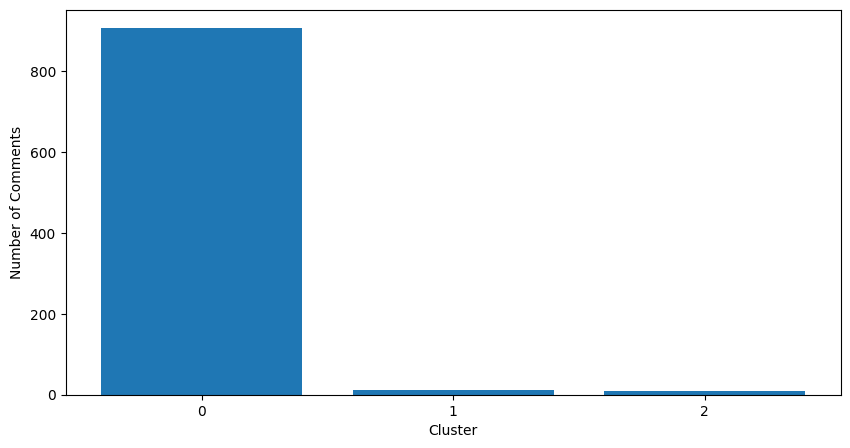

Cluster sizes: 0    906
1     11
2      8
Name: count, dtype: int64


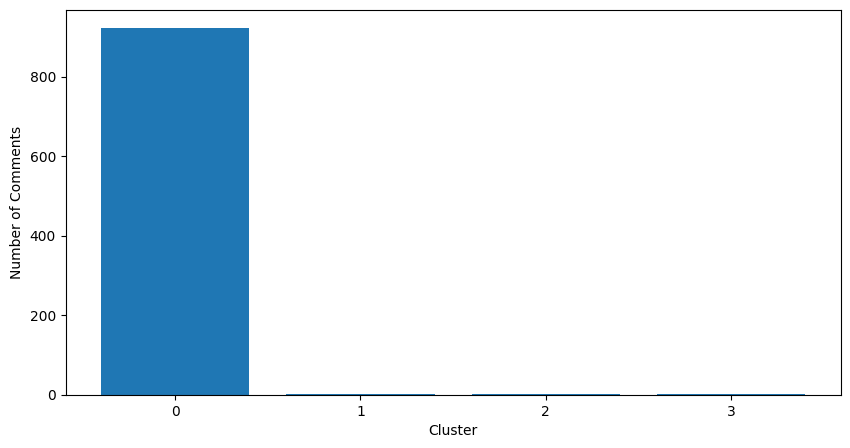

Cluster sizes: 0    922
3      1
1      1
2      1
Name: count, dtype: int64


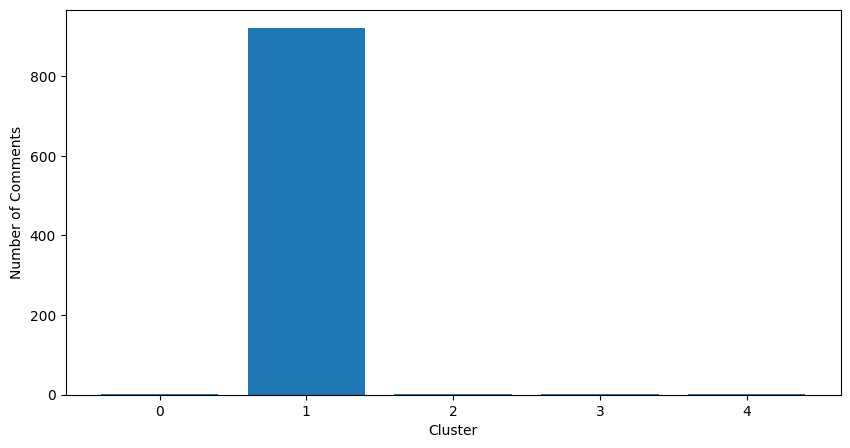

Cluster sizes: 1    921
3      1
4      1
2      1
0      1
Name: count, dtype: int64


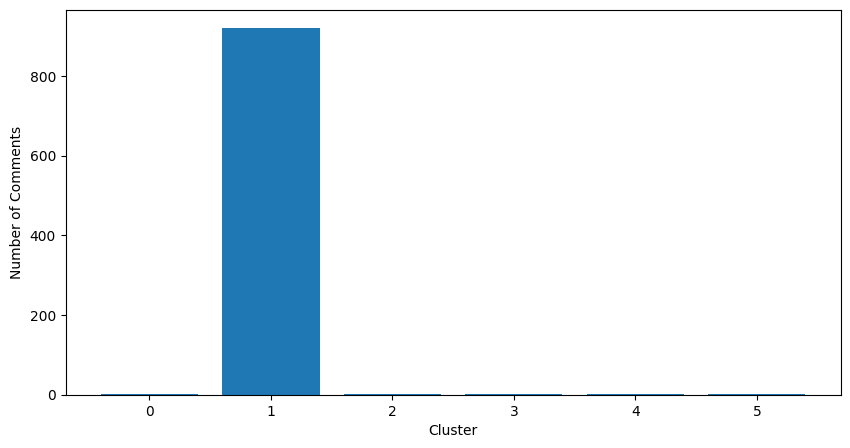

Cluster sizes: 1    920
0      1
4      1
2      1
3      1
5      1
Name: count, dtype: int64


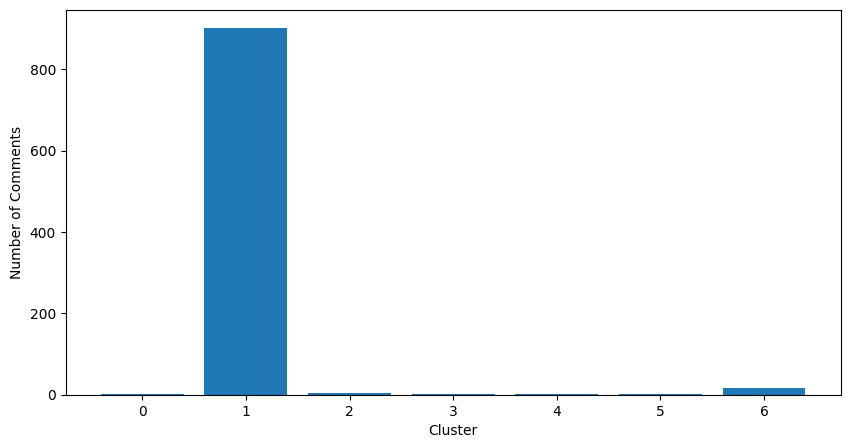

Cluster sizes: 1    901
6     16
2      4
3      1
0      1
5      1
4      1
Name: count, dtype: int64


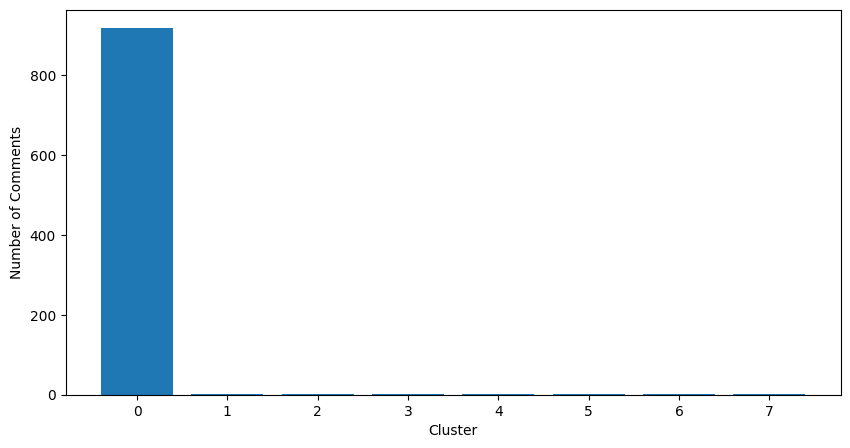

Cluster sizes: 0    918
7      1
4      1
3      1
2      1
5      1
1      1
6      1
Name: count, dtype: int64


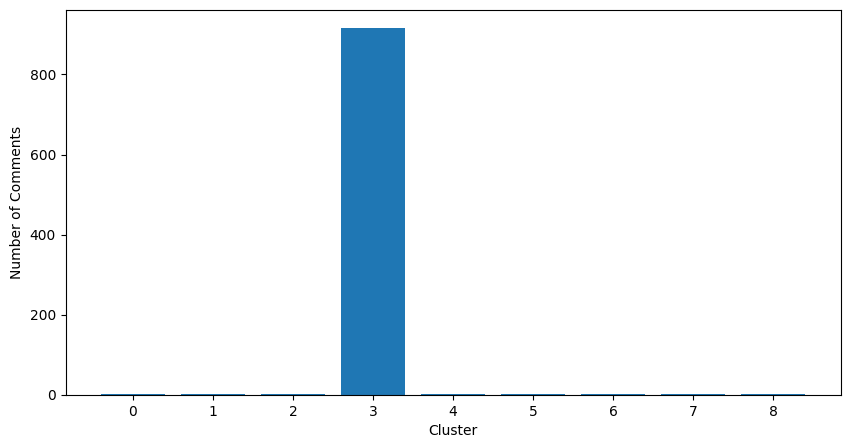

Cluster sizes: 3    916
0      2
5      1
6      1
2      1
8      1
7      1
4      1
1      1
Name: count, dtype: int64


In [7]:
#Plot the number of comments for each cluster
for i in clustering_results:
    cluster_sizes = pd.Series(i.labels_).value_counts()
    plt.figure(figsize=(10, 5))
    plt.bar(cluster_sizes.index, cluster_sizes.values)
    #plt.title(f"Number of Comments in Each Cluster (k={numberOfChoosenClusters})")
    plt.xlabel("Cluster")
    plt.ylabel("Number of Comments")
    plt.xticks(cluster_sizes.index)
    plt.show()
    print("Cluster sizes:", cluster_sizes)

In [ ]:
#when using PCA/SVD we get less outliers
from sklearn.cluster import HDBSCAN

hdbscan_results = []

hdbscan = HDBSCAN(min_samples=3)
hdbscan_results=hdbscan.fit(X)

score = silhouette_score(X, hdbscan_results.labels_)

# compute silhouette score only of clustered samples (not noise, i.e., not -1)
mask = hdbscan_results.labels_ != -1
score_No_Outliers = silhouette_score(X[mask], hdbscan_results.labels_[mask])
print("Silhouette score:", score)
print("Silhouette score (clustered samples only):", score_No_Outliers)
print("Number of outliers detected:", np.sum(hdbscan_results.labels_ == -1))

Silhouette score: -0.3355379805713376
Silhouette score (clustered samples only): -0.21171700909038563
Number of outliers detected: 6976


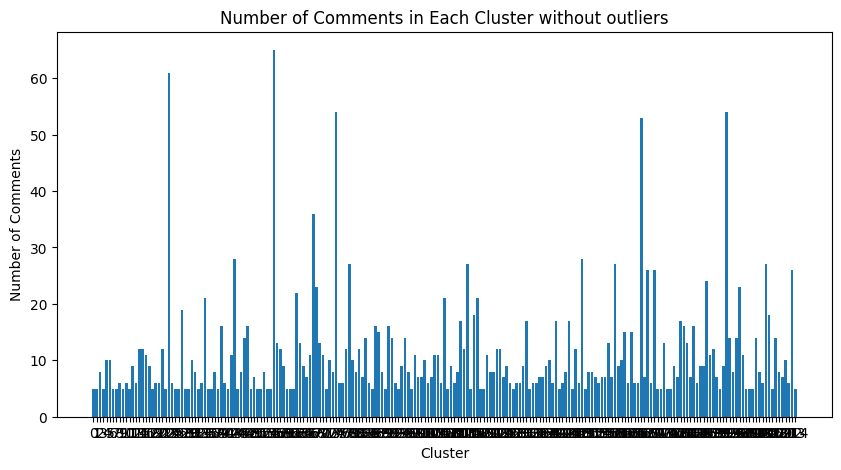

Cluster sizes: 55     65
23     61
74     54
193    54
167    53
       ..
28      5
3       5
59      5
44      5
201     5
Name: count, Length: 215, dtype: int64


In [5]:
cluster_sizes = pd.Series(hdbscan_results.labels_[mask]).value_counts()
plt.figure(figsize=(10, 5))
plt.bar(cluster_sizes.index, cluster_sizes.values)
plt.title(f"Number of Comments in Each Cluster without outliers")
plt.xlabel("Cluster")
plt.ylabel("Number of Comments")
plt.xticks(cluster_sizes.index)
plt.show()
print("Cluster sizes:", cluster_sizes)

In [10]:
import pickle

with open("kmeans_clustering_results.pkl", "wb") as f:
    pickle.dump(clustering_results, f)

with open("hdbscan_results.pkl", "wb") as f:
    pickle.dump(hdbscan_results, f)